In [1]:
import sys
sys.path.append('../src')

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
datasets = ['ohsumed-single', 'agnews', 'r8', 'r52']

dataset_map = {
    'ohsumed-single': 'Ohsumed',
    'agnews': 'AGNews',
    'r8': 'R8',
    'r52': 'R52'
}

setting_name_map = {
    'llm_only': 'LLM only',

    'base': 'Pseudo-labels only',
    'examples': 'Aug. examples',
    'hetero': 'Het. nodes',
    'hetero_examples': 'Het. nodes + aug. examples',
    # 'examples_as_hetero': 'EaH',

    'base_llm_labels_100_no_knn_labels': '100 LLM labs. (w/o kNN labs.)',
    'base_llm_labels_1000_no_knn_labels': '1K LLM labs. (w/o kNN labs.)',
    'examples_llm_labels_100_no_knn_labels': 'Aug. exs. + 100 LLM labs. (w/o kNN labs.)',
    'examples_llm_labels_1000_no_knn_labels': 'Aug. exs. + 1K LLM labs. (w/o kNN labs.)',
    'hetero_llm_labels_100_no_knn_labels': 'Het. nodes + 100 LLM labs. (w/o kNN labs.)',
    'hetero_llm_labels_1000_no_knn_labels': 'Het. nodes + 1K LLM labs. (w/o kNN labs.)',
    'hetero_examples_llm_labels_100_no_knn_labels': 'Het. nodes + aug. exs. + 100 LLM labs. (w/o kNN labs.)',
    'hetero_examples_llm_labels_1000_no_knn_labels': 'Het. nodes + aug. exs. + 1K LLM labs. (w/o kNN labs.)',

    # 'base_llm_labels_100_examples_knn_labels': '100 LLM labs. (examples kNN labs.)',
    # 'base_llm_labels_1000_examples_knn_labels': '1K LLM labs. (examples kNN labs.)',
    # 'examples_llm_labels_100_examples_knn_labels': 'Aug. exs. + 100 LLM labs. (examples kNN labs.)',
    # 'examples_llm_labels_1000_examples_knn_labels': 'Aug. exs. + 1K LLM labs. (examples kNN labs.)',
    # 'hetero_llm_labels_100_examples_knn_labels': 'Het. nodes + 100 LLM labs. (examples kNN labs.)',
    # 'hetero_llm_labels_1000_examples_knn_labels': 'Het. nodes + 1K LLM labs. (examples kNN labs.)',
    # 'hetero_examples_llm_labels_100_examples_knn_labels': 'Het. nodes + aug. exs. + 100 LLM labs. (examples kNN labs.)',
    # 'hetero_examples_llm_labels_1000_examples_knn_labels': 'Het. nodes + aug. exs. + 1K LLM labs. (examples kNN labs.)',

    # 'base_llm_labels_100_agreement_only': 'B+100-A',
    # 'base_llm_labels_1000_agreement_only': 'B+1K-A',
    # 'examples_llm_labels_100_agreement_only': 'E+100-A',
    # 'examples_llm_labels_1000_agreement_only': 'E+1K-A',
    # 'hetero_llm_labels_100_agreement_only': 'H+100-A',
    # 'hetero_llm_labels_1000_agreement_only': 'H+1K-A',
    # 'hetero_examples_llm_labels_100_agreement_only': 'HE+100-A',
    # 'hetero_examples_llm_labels_1000_agreement_only': 'HE+1K-A',

    # 'base_examples_knn_labels': 'B-EK',
    # 'examples_examples_knn_labels': 'E-EK',
    # 'hetero_examples_knn_labels': 'H-EK',
    # 'hetero_examples_examples_knn_labels': 'HE-EK',
    # 'base_llm_labels_100_examples_knn_labels': 'B+100-EK',
    # 'base_llm_labels_1000_examples_knn_labels': 'B+1K-EK',
    # 'examples_llm_labels_100_examples_knn_labels': 'E+100-EK',
    # 'examples_llm_labels_1000_examples_knn_labels': 'E+1K-EK',
    # 'hetero_llm_labels_100_examples_knn_labels': 'H+100-EK',
    # 'hetero_llm_labels_1000_examples_knn_labels': 'H+1K-EK',
    # 'hetero_examples_llm_labels_100_examples_knn_labels': 'HE+100-EK',
    # 'hetero_examples_llm_labels_1000_examples_knn_labels': 'HE+1K-EK',

    'base_llm_labels_100': '100 LLM labs.',
    'base_llm_labels_1000': '1K LLM labs.',
    'examples_llm_labels_100': 'Aug. exs. + 100 LLM labs.',
    'examples_llm_labels_1000': 'Aug. exs. + 1K LLM labs.',
    'hetero_llm_labels_100': 'Het. nodes + 100 LLM labs.',
    'hetero_llm_labels_1000': 'Het. nodes + 1K LLM labs.',
    'hetero_examples_llm_labels_100': 'Het. nodes + aug. exs. + 100 LLM labs.',
    'hetero_examples_llm_labels_1000': 'Het. nodes + aug. exs. + 1K LLM labs.',

    # 'base_gt_descs': 'B-GTD',
    # 'examples_gt_descs': 'E-GTD',
    # 'hetero_gt_descs': 'H-GTD',
    # 'hetero_examples_gt_descs': 'HE-GTD',
    # 'base_llm_labels_100_gt_descs': 'B+100-GTD',
    # 'base_llm_labels_1000_gt_descs': 'B+1K-GTD',
    # 'examples_llm_labels_100_gt_descs': 'E+100-GTD',
    # 'examples_llm_labels_1000_gt_descs': 'E+1K-GTD',
    # 'hetero_llm_labels_100_gt_descs': 'H+100-GTD',
    # 'hetero_llm_labels_1000_gt_descs': 'H+1K-GTD',
    # 'hetero_examples_llm_labels_100_gt_descs': 'HE+100-GTD',
    # 'hetero_examples_llm_labels_1000_gt_descs': 'HE+1K-GTD',
    
    # 'examples_as_hetero_llm_labels_100': 'EaH+100',
    # 'examples_as_hetero_llm_labels_1000': 'EaH+1K',

}

base_dir = '../outputs'

In [26]:
def load_f1(dataset, setting, base_dir, prefix='desc_sim_'):
    prefix = prefix or ''

    path = os.path.join(
        base_dir,
        dataset,
        f'{prefix}{setting}',
        'results.csv'
    )

    if not os.path.exists(path):
        return None, None

    df = pd.read_csv(path)
    df = df.dropna(subset=['f1-macro'])

    return df['f1-macro'].tolist()

def build_df(datasets, settings, base_dir, prefix='desc_sim_'):
    rows = []
    for dataset in datasets:
        for setting in settings:
            f1_scores = load_f1(dataset, setting, base_dir, prefix)
            for score in f1_scores:
                rows.append({
                    'dataset': dataset_map[dataset],
                    'setting': setting,
                    'score': score
                })

    df = pd.DataFrame(rows)

    return df

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt


def underline_text(text):
    return ''.join(char + '\u0332' for char in text)


def plot_df(df, as_lines={}, setting_name_map={}, show_values=True, hue=None, x='setting'):
    settings = list(df['setting'].unique())
    datasets = list(df['dataset'].unique())

    width = max(int(len(settings)*0.4), 5)
    fig, axes = plt.subplots(nrows=4, figsize=(width, 10))
    axes = axes.flatten()

    for idx, dataset in enumerate(datasets):
        ax = axes[idx]
        data = df[df['dataset'] == dataset].reset_index(drop=True)
        data['score'] = 100*data['score']
        
        as_line_scores = {}
        for setting in as_lines:
            mean = data[data['setting'] == setting]['score'].mean()
            std = data[data['setting'] == setting]['score'].std()
            as_line_scores[setting] = (mean, std)
            data = data[data['setting'] != setting].reset_index()

        best = data.groupby('setting').mean(numeric_only=True).reset_index()['score'].max()

        for setting,color in as_lines.items():
            score = as_line_scores[setting][0]
            std = as_line_scores[setting][1]
            ax.axhline(y=score, color=color)
            ax.annotate(xy=(0, score), xytext=(-10, 2), textcoords='offset points', text=f'{setting_name_map[setting]} = {score:.1f}', ha='center', va='bottom', fontsize=8, color=color)

        sns.barplot(
            data=data.replace(setting_name_map),
            x=x,
            y='score',
            hue=hue, 
            ax=ax,
            errorbar='sd',
            palette='Paired' if hue else None
        )
        patterns = ['//', '\\\\', '..', 'xx', '*']
        num_bars_per_bin = len(data[hue].unique()) if hue else 1
        num_bins = len(data[x].unique())
        if num_bars_per_bin > 1:
            for i, patch in enumerate(ax.patches):
                pat = patterns[i//num_bins] if i < len(ax.patches) - num_bars_per_bin else patterns[i%num_bins]
                patch.set_hatch(pat)
                patch.set_edgecolor((0, 0, 0, 0.5)) # Good contrast for hatches

        if show_values:
            l = len(as_lines)
            for c in ax.containers:
                for d in c.datavalues.tolist():
                    sd = ax.lines[l].get_ydata()[1] - d
                    xy = (ax.lines[l].get_xdata()[0], ax.lines[l].get_ydata()[1])
                    xytext = (0, 2)
                    text = f"{d:.1f}"
                    fontweight = 'bold' if abs(d - best) < 1e-5 else 'normal'
                    ax.annotate(xy=xy, xytext=xytext, 
                                textcoords='offset points', 
                                text=text, va='bottom', ha='center', fontsize=8, weight=fontweight)
                    l += 1

        y_min = (data.groupby('setting').mean(numeric_only=True).reset_index()['score'] - data.groupby('setting').std(numeric_only=True).reset_index()['score']).min()
        y_max = (data.groupby('setting').mean(numeric_only=True).reset_index()['score'] + data.groupby('setting').std(numeric_only=True).reset_index()['score']).max()

        ax.set_title(dataset)
        ax.set_ylim(y_min - 0.1*(y_max-y_min), y_max + 0.1*(y_max-y_min))
        ax.set_xlabel('')
        ax.set_ylabel('F1-macro' if idx % 2 == 0 else '')
        ax.tick_params(axis='x')

        if idx < 2:
            ax.set_xticks([])

        if ax.get_legend():
            ax.get_legend().remove()

        sns.despine(ax=ax)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper left', bbox_to_anchor=(1.0, 1.0)).set_title(hue)

    fig.tight_layout()

    return fig

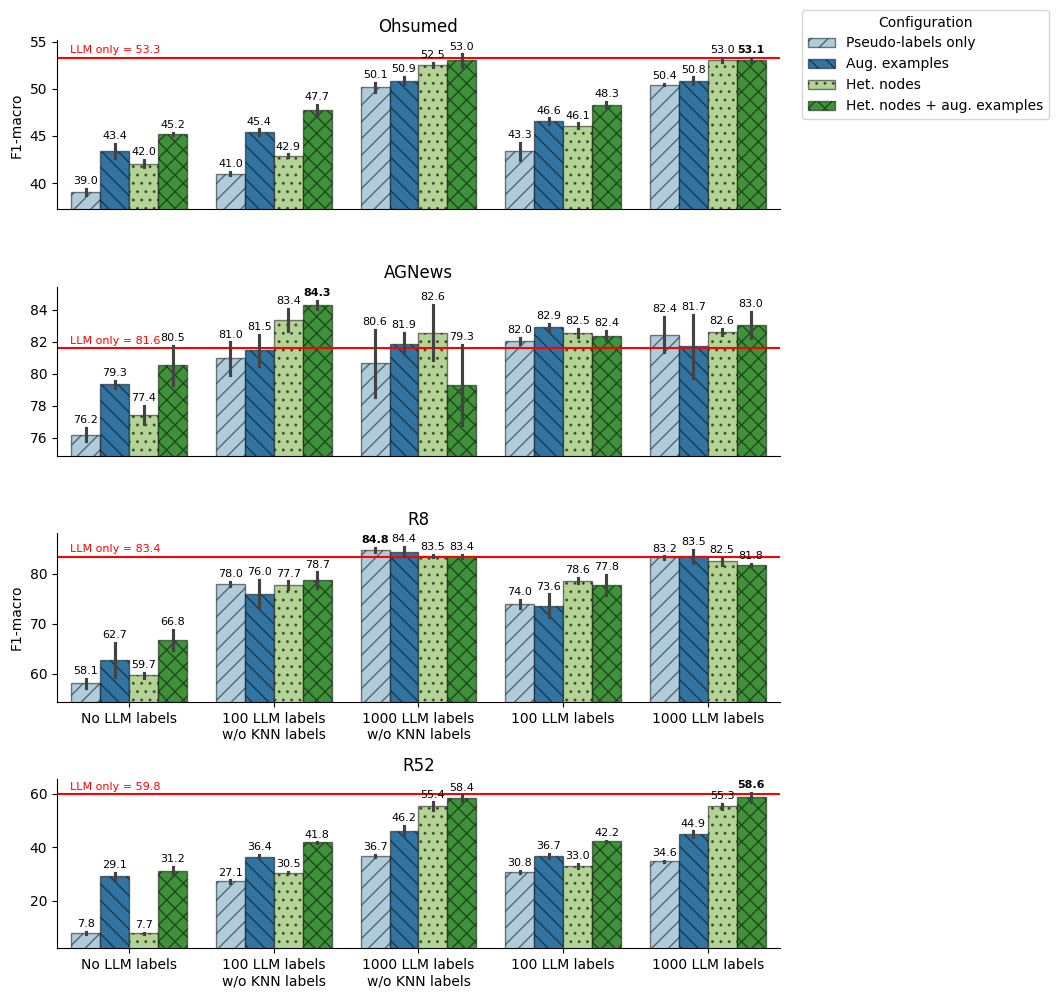

In [ ]:
df_plot = pd.concat((
    build_df(datasets, setting_name_map.keys(), f'../outputs/AxionML--Qwen3.5-9B-NVFP4+Qwen--Qwen3-VL-Embedding-2B'),
    build_df(datasets, ['HGAT', 'text_gcn'], f'../outputs/external')
))

df_plot['Configuration'] = df_plot['setting'].str.split('_llm').map(lambda x: x[0])

def setting_to_config(setting):
    if 'no_knn_labels' in setting:
        if '1000' in setting:
            return '1000 LLM labels\nw/o KNN labels'
        else:
            return '100 LLM labels\nw/o KNN labels'
    
    if 'knn_labels' in setting:
        if '1000' in setting:
            return '1000 LLM labels\nexample KNN labels'
        else:
            return '100 LLM labels\nexample KNN labels'

    if '1000' in setting:
        return '1000 LLM labels'
    elif '100' in setting:
        return '100 LLM labels'

    return 'No LLM labels'

df_plot['config'] = df_plot['setting'].map(setting_to_config)

settings = [
    'llm_only',
    'base', 'base_llm_labels_100_no_knn_labels', 'base_llm_labels_100', 'base_llm_labels_1000_no_knn_labels', 'base_llm_labels_1000',
    'examples', 'examples_llm_labels_100_no_knn_labels', 'examples_llm_labels_100', 'examples_llm_labels_1000_no_knn_labels', 'examples_llm_labels_1000',
    'hetero', 'hetero_llm_labels_100_no_knn_labels', 'hetero_llm_labels_100', 'hetero_llm_labels_1000_no_knn_labels', 'hetero_llm_labels_1000',
    'hetero_examples', 'hetero_examples_llm_labels_100_no_knn_labels', 'hetero_examples_llm_labels_100', 'hetero_examples_llm_labels_1000_no_knn_labels', 'hetero_examples_llm_labels_1000',
]

as_lines = {
    'llm_only': 'red'
}

name_map = {
    'llm_only': 'LLM only',
    'base': 'Pseudo-labels only',
    'examples': 'Aug. examples',
    'hetero': 'Het. nodes',
    'hetero_examples': 'Het. nodes + aug. examples',
}

fig = plot_df(df_plot, as_lines, name_map, show_values=True, hue='Configuration', x='config')

# fig.savefig('figures/main.pdf', bbox_inches='tight')

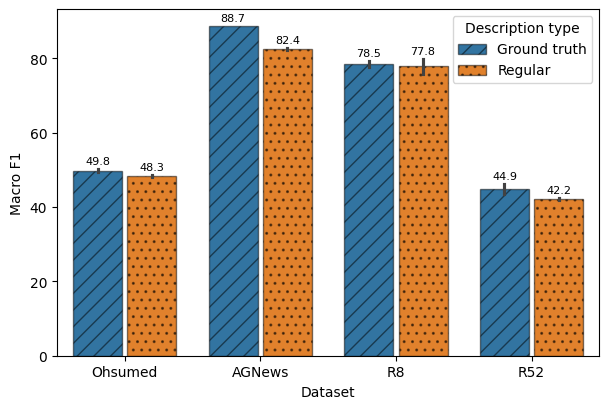

In [10]:
settings = [
    'hetero_examples_llm_labels_100_gt_descs',
    'hetero_examples_llm_labels_100'
]
df_plot = build_df(datasets, settings, f'../outputs/AxionML--Qwen3.5-9B-NVFP4+Qwen--Qwen3-VL-Embedding-2B')

name_map = {
    'hetero_examples_llm_labels_100_gt_descs': 'Ground truth',
    'hetero_examples_llm_labels_100': 'Regular',
}

# plot_df(df_plot, setting_name_map=name_map, x='setting')

df_plot['setting'] = df_plot['setting'].replace(name_map)
df_plot['score'] = 100*df_plot['score']

fig,ax = plt.subplots(figsize=(7, 4.5))
g = sns.barplot(df_plot, x='dataset', hue='setting', y='score', errorbar='sd', ax=ax, gap=.1)

patterns = ['//', '..', 'xx', '*']
for i, patch in enumerate(g.patches):
    pat = patterns[i//4] if i < len(g.patches) - 2 else patterns[i%2]
    patch.set_hatch(pat)
    patch.set_edgecolor((0, 0, 0, 0.5))

g.legend(title='Description type')

g.set_xlabel('Dataset')
g.set_ylabel('Macro F1')

l = 0
for c in g.containers:
    for d in c.datavalues.tolist():
        sd = g.lines[l].get_ydata()[1] - d
        xy = (g.lines[l].get_xdata()[0], g.lines[l].get_ydata()[1])
        xytext = (0, 2)
        text = f"{d:.1f}"
        g.annotate(xy=xy, xytext=xytext, 
                   textcoords='offset points', 
                   text=text, va='bottom', ha='center', fontsize=8)
        l += 1

g.figure.savefig('figures/gt_descs.pdf')

In [28]:
import pandas as pd


def generate_latex_results_table_transposed(df, dataset_col='dataset', method_col='setting', score_col='score', decimals=2):

    agg = df.groupby([dataset_col, method_col])[score_col].agg(['mean', 'std']).reset_index()

    methods = df[method_col].unique()
    datasets = df[dataset_col].unique()

    table = pd.DataFrame(index=methods, columns=datasets)

    for dataset in datasets:
        subset = agg[agg[dataset_col] == dataset].copy()

        ranking = subset.sort_values('mean', ascending=False)[method_col].tolist()

        best = ranking[0]
        second = ranking[1] if len(ranking) > 1 else None

        for _, row in subset.iterrows():
            method = row[method_col]

            mean = 100 * row['mean']
            std = 100 * row['std']

            value = f'{mean:.{decimals}f}$\\pm${std:.{decimals}f}'

            if method == best:
                value = f'\\textbf{{{value}}}'
            elif method == second:
                value = f'\\underline{{{value}}}'

            table.loc[method, dataset] = value

    latex = table.to_latex(escape=False, na_rep='-')

    return latex

method_name = '<method>'

setting_map = {
    'llm_only': 'LLM only',

    'base_llm_labels_100': f'{method_name} w/o aug. het.',
    'examples_llm_labels_100': f'{method_name} w/o het.',
    'hetero_llm_labels_100': f'{method_name} w/o aug.',
    'hetero_examples_llm_labels_100': f'{method_name}',

    'base_llm_labels_100_no_knn_labels': f'{method_name} (no kNN) w/o aug. het.*',
    'examples_llm_labels_100_no_knn_labels': f'{method_name} (no kNN) w/o het.',
    'hetero_llm_labels_100_no_knn_labels': f'{method_name} (no kNN) w/o aug.',
    'hetero_examples_llm_labels_100_no_knn_labels': f'{method_name} (no kNN)',

    'textgcn': 'TextGCN',
    'hgat': 'HGAT',
}

df_table = pd.concat((
    build_df(datasets, setting_name_map.keys(), f'../outputs/AxionML--Qwen3.5-9B-NVFP4+Qwen--Qwen3-VL-Embedding-2B'),
    build_df(datasets, ['hgat', 'textgcn'], f'../outputs/external', prefix=None)
))

df_table['setting'] = df_table['setting'].replace(setting_map)
latex = generate_latex_results_table_transposed(
    df_table,
    dataset_col='dataset',
    method_col='setting',
    score_col='score',
    decimals=1,
)

print(latex)

\begin{tabular}{lllll}
\toprule
 & Ohsumed & AGNews & R8 & R52 \\
\midrule
LLM only & \textbf{53.3$\pm$0.2} & 81.6$\pm$0.0 & 83.4$\pm$0.0 & \textbf{59.8$\pm$0.0} \\
base & 39.0$\pm$0.3 & 76.2$\pm$0.4 & 58.1$\pm$0.9 & 7.8$\pm$0.3 \\
examples & 43.4$\pm$0.8 & 79.3$\pm$0.2 & 62.7$\pm$3.4 & 29.1$\pm$1.2 \\
hetero & 42.0$\pm$0.4 & 77.4$\pm$0.5 & 59.7$\pm$0.5 & 7.7$\pm$0.2 \\
hetero_examples & 45.2$\pm$0.1 & 80.5$\pm$1.2 & 66.8$\pm$2.0 & 31.2$\pm$1.4 \\
<method> (no kNN) w/o aug. het.* & 41.0$\pm$0.2 & 81.0$\pm$1.0 & 78.0$\pm$0.4 & 27.1$\pm$0.4 \\
base_llm_labels_1000_no_knn_labels & 50.1$\pm$0.5 & 80.6$\pm$2.1 & \textbf{84.8$\pm$0.4} & 36.7$\pm$0.4 \\
<method> (no kNN) w/o het. & 45.4$\pm$0.3 & 81.5$\pm$1.0 & 76.0$\pm$2.7 & 36.4$\pm$0.6 \\
examples_llm_labels_1000_no_knn_labels & 50.9$\pm$0.4 & 81.9$\pm$0.7 & \underline{84.4$\pm$0.9} & 46.2$\pm$1.7 \\
<method> (no kNN) w/o aug. & 42.9$\pm$0.1 & \underline{83.4$\pm$0.7} & 77.7$\pm$0.8 & 30.5$\pm$0.2 \\
hetero_llm_labels_1000_no_knn_labels & 

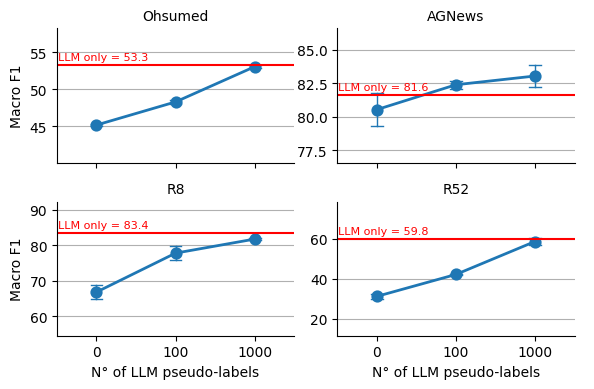

In [13]:
n_labels_map = {
    'llm_only': 0,

    'base': 0,
    'examples': 0,
    'hetero': 0,
    'hetero_examples': 0,

    'base_llm_labels_100': 100,
    'examples_llm_labels_100': 100,
    'hetero_llm_labels_100': 100,
    'hetero_examples_llm_labels_100': 100,

    'base_llm_labels_1000': 1000,
    'examples_llm_labels_1000': 1000,
    'hetero_llm_labels_1000': 1000,
    'hetero_examples_llm_labels_1000': 1000,
}

setting_map = {
    'llm_only': 'LLM only',

    'base': 'No het. aug.',
    'examples': 'No het.',
    'hetero': 'No aug.',
    'hetero_examples': '<method>',

    'base_llm_labels_100': 'No het. aug.',
    'examples_llm_labels_100': 'No het.',
    'hetero_llm_labels_100': 'No aug.',
    'hetero_examples_llm_labels_100': '<method>',

    'base_llm_labels_1000': 'No het. aug.',
    'examples_llm_labels_1000': 'No het.',
    'hetero_llm_labels_1000': 'No aug.',
    'hetero_examples_llm_labels_1000': '<method>',
}

df_plot = build_df(datasets, n_labels_map.keys(), f'../outputs/AxionML--Qwen3.5-9B-NVFP4+Qwen--Qwen3-VL-Embedding-2B')

df_plot['n_pseudo_labels'] = df_plot['setting'].replace(n_labels_map)
df_plot['setting'] = df_plot['setting'].replace(setting_map)
df_plot['score'] = 100*df_plot['score']

g = sns.catplot(
    df_plot[df_plot['setting'] == '<method>'], 
    x='n_pseudo_labels', y='score',
    col='dataset', 
    kind='point', 
    col_wrap=2, height=2, aspect=1.5,
    capsize=0.15,
    errorbar='sd',
    sharex=True, sharey=False,
    err_kws={'linewidth': 1.0}
)

g.set_titles('{col_name}')
g.set_ylabels('Macro F1')
g.set_xlabels('N° of LLM pseudo-labels')

for i,ax in enumerate(g.axes):
    dataset = df_plot['dataset'].unique()[i]
    mean_llm_only = df_plot[(df_plot['dataset'] == dataset) & (df_plot['setting'] == 'LLM only')]['score'].mean()
    
    for line in ax.lines:
        if line.get_linewidth() > 1.5:
            plt.setp(line, linewidth=2.0)
    ax.grid(True, axis='y')

    lower, upper = ax.get_ylim()
    diff = upper - lower

    ax.set_ylim(lower - 0.5*diff, upper + 0.5*diff)

    ax.axhline(mean_llm_only, color='red')
    ax.annotate(xy=(0, mean_llm_only), xytext=(5, 2), textcoords='offset points', text=f'LLM only = {mean_llm_only:.1f}', ha='center', va='bottom', fontsize=8, color='red')

g.figure.savefig('figures/n_pseudo.pdf')

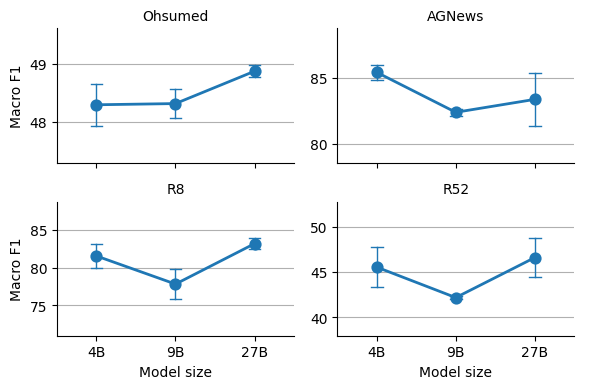

In [14]:
df_llms = pd.DataFrame()

settings = [
    'base',
    'examples',
    'hetero',
    'hetero_examples',
    'base_llm_labels_100',
    'base_llm_labels_1000',
    'examples_llm_labels_100',
    'examples_llm_labels_1000',
    'hetero_llm_labels_100',
    'hetero_llm_labels_1000',
    'hetero_examples_llm_labels_100',
    'hetero_examples_llm_labels_1000'
]

sentence_model = 'Qwen/Qwen3-VL-Embedding-2B'
for llm in ['cosmicproc/Qwen3.5-4B-NVFP4', 'AxionML/Qwen3.5-9B-NVFP4', 'Intel/Qwen3.5-27B-int4-AutoRound']:
    llm = llm.replace('/', '--')
    sentence_model = sentence_model.replace('/', '--')

    base_dir = f'../outputs/{llm}+{sentence_model}'
    df_llm = build_df(datasets, settings, base_dir)
    df_llm['llm'] = llm
    df_llms = pd.concat((df_llms, df_llm))

df_llms.reset_index(inplace=True)

def get_llm_size(llm):
    if '4B' in llm: return '4B'
    if '9B' in llm: return '9B'
    if '27B' in llm: return '27B'

df_llms['model_size'] = df_llms['llm'].map(get_llm_size)
df_llms['score'] = 100*df_llms['score']

g = sns.catplot(
    df_llms[df_llms['setting'] == 'hetero_examples_llm_labels_100'], 
    x='model_size', y='score', 
    col='dataset', 
    kind='point', 
    col_wrap=2, height=2, aspect=1.5,
    capsize=0.15,
    errorbar='sd',
    sharex=True, sharey=False,
    err_kws={'linewidth': 1.0}
)

g.set_titles('{col_name}')
g.set_ylabels('Macro F1')
g.set_xlabels('Model size')

for ax in g.axes:
    for line in ax.lines:
        if line.get_linewidth() > 1.5:
            plt.setp(line, linewidth=2.0)
    ax.grid(True, axis='y')

    lower, upper = ax.get_ylim()
    diff = upper - lower

    ax.set_ylim(lower - 0.5*diff, upper + 0.5*diff)

g.figure.savefig('figures/llm_size.pdf')

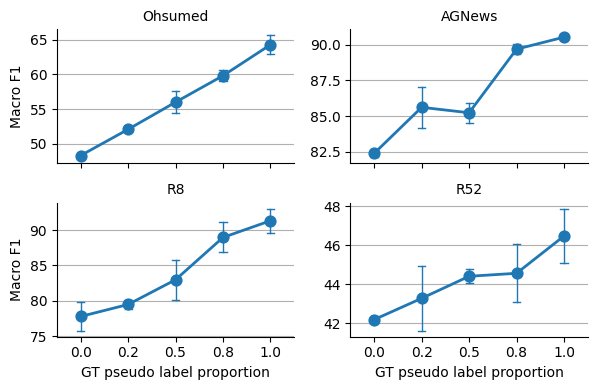

In [17]:
base_settings = [
    'base',
    'examples',
    'hetero',
    'hetero_examples',
    'base_llm_labels_100',
    'base_llm_labels_1000',
    'examples_llm_labels_100',
    'examples_llm_labels_1000',
    'hetero_llm_labels_100',
    'hetero_llm_labels_1000',
    'hetero_examples_llm_labels_100',
    'hetero_examples_llm_labels_1000'
]
map = {k: v for k,v in setting_name_map.items() if k in settings}

sentence_model = 'Qwen--Qwen3-VL-Embedding-2B'
llm = 'AxionML--Qwen3.5-9B-NVFP4'
base_dir = f'../outputs/{llm}+{sentence_model}'

df_prop = build_df(datasets, base_settings, base_dir)
df_prop['prop'] = 0

for prop in [0.2, 0.5, 0.8, 1.0]:
    settings = [s + f'_gt_prop_{prop:.1f}' for s in base_settings]

    curr_df = build_df(datasets, settings, base_dir)
    curr_df['prop'] = prop
    curr_df['setting'] = curr_df['setting'].str.replace(f'_gt_prop_{prop:.1f}', '')
    df_prop = pd.concat((df_prop, curr_df))

df_prop.reset_index(inplace=True)
df_prop['score'] = 100*df_prop['score']

g = sns.catplot(
    df_prop[df_prop['setting'] == 'hetero_examples_llm_labels_100'], 
    x='prop', y='score', 
    col='dataset', 
    kind='point',
    errorbar='sd',
    col_wrap=2, height=2, aspect=1.5,
    sharey=False,
    err_kws={'linewidth': 1.0},
    capsize=0.15
)

g.set_titles('{col_name}')
g.set_ylabels('Macro F1')
g.set_xlabels('GT pseudo label proportion')

for ax in g.axes:
    for line in ax.lines:
        if line.get_linewidth() > 1.5:
            plt.setp(line, linewidth=2.0)
    ax.grid(True, axis='y')

g.figure.savefig('figures/gt_prop.pdf')

### Embeddings

In [29]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE


def plot_embedding_sets(embedding_sets, label_names=None, method='tsne', figsize=(12, 12), ax=None, random_state=42):
    if 'embeddings' in embedding_sets:
        embedding_sets = {'': embedding_sets}

    processed = {}
    for set_name, data in embedding_sets.items():

        embs = data['embeddings']
        labels = data['labels']

        if hasattr(embs, 'detach'):
            embs = embs.detach().cpu().numpy()

        if hasattr(labels, 'detach'):
            labels = labels.detach().cpu().numpy()

        embs = np.asarray(embs)
        labels = np.asarray(labels)

        processed[set_name] = {
            'embeddings': embs,
            'labels': labels,
        }

    all_embeddings = np.concatenate([v['embeddings'] for v in processed.values()],axis=0)

    if method == 'tsne':
        reducer = TSNE(n_components=2, random_state=random_state, init='pca', learning_rate='auto')
        X2d = reducer.fit_transform(all_embeddings)

    elif method == 'pca':
        from sklearn.decomposition import PCA

        reducer = PCA(n_components=2)
        X2d = reducer.fit_transform(all_embeddings)

    start = 0

    for set_name, data in processed.items():
        n = len(data['embeddings'])

        processed[set_name]['embeddings_2d'] = X2d[start:start+n]

        start += n

    all_labels = np.concatenate([v['labels'] for v in processed.values()])
    unique_labels = sorted(np.unique(all_labels))

    colors = (list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors) + list(plt.cm.tab20c.colors))

    if len(unique_labels) > len(colors):
        raise ValueError(
            f'Too many labels ({len(unique_labels)}). '
            f'Maximum supported is {len(colors)}.'
        )

    label_to_color = { label: colors[i] for i, label in enumerate(unique_labels) }

    markers = ['o', 'D', 's', '^', 'v', 'P', 'X', '*', '<', '>']
    alphas = np.linspace(0.35, 1.0, len(processed)) if len(processed) > 1 else [1]
    sizes = np.linspace(40, 120, len(processed))

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    for idx, (set_name, data) in enumerate(processed.items()):
        x_set = data['embeddings_2d']
        labels = data['labels']

        marker = markers[idx % len(markers)]
        alpha = alphas[idx]
        size = sizes[idx]

        for label in np.unique(labels):
            mask = labels == label

            name = label_names[label] if label_names is not None else str(label)
            legend_label = name + (f' ({set_name})' if set_name else '')

            ax.scatter(
                x_set[mask, 0],
                x_set[mask, 1],
                c=[label_to_color[label]],
                marker=marker,
                alpha=float(alpha),
                s=float(size),
                edgecolors='black',
                linewidths=0.4,
                label=legend_label,
            )

    ax.set_title('Embedding Visualization')
    ax.set_xlabel('Dim 1')
    ax.set_ylabel('Dim 2')

    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(), bbox_to_anchor=(1.05, 1), loc='upper left')

    fig.tight_layout()

/tmp/ipykernel_3226215/2607973862.py:108: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()
/tmp/ipykernel_3226215/2607973862.py:108: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


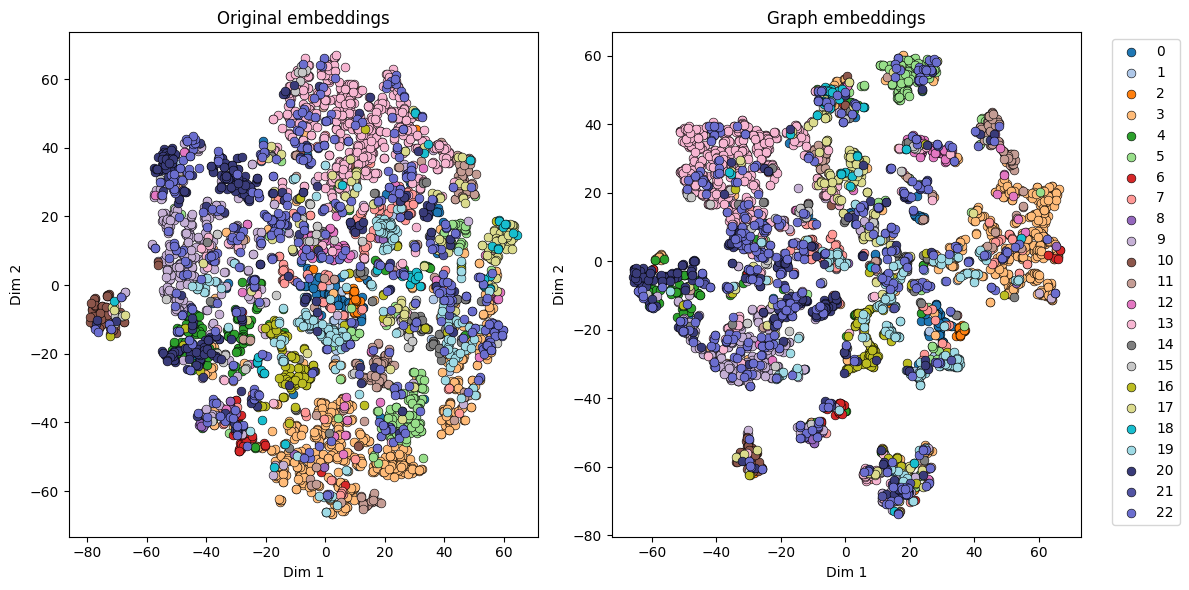

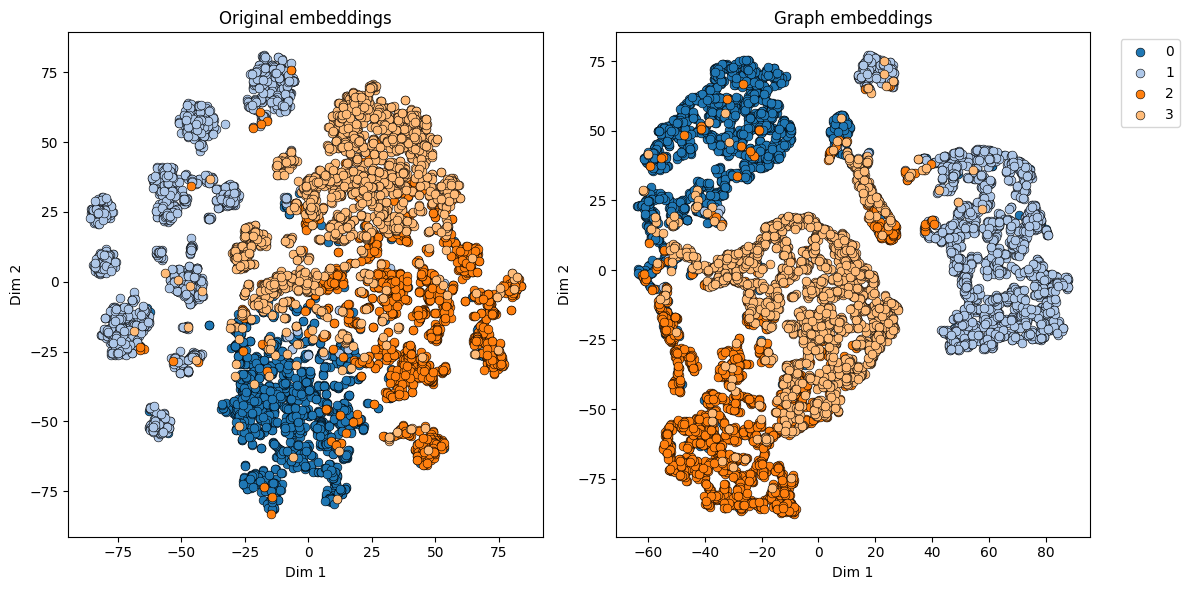

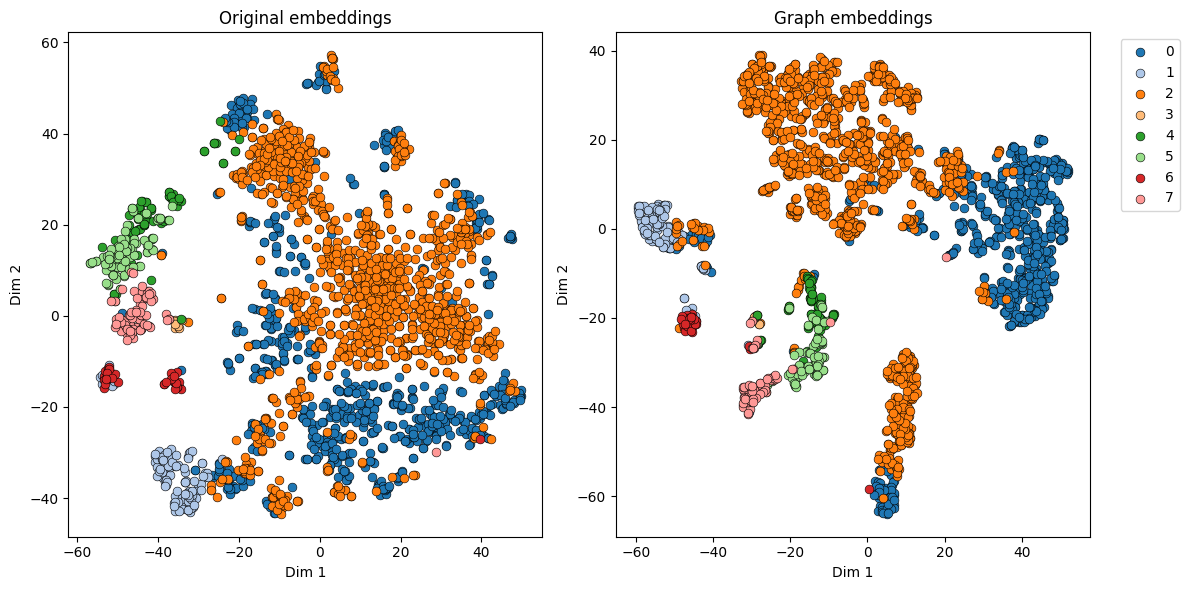

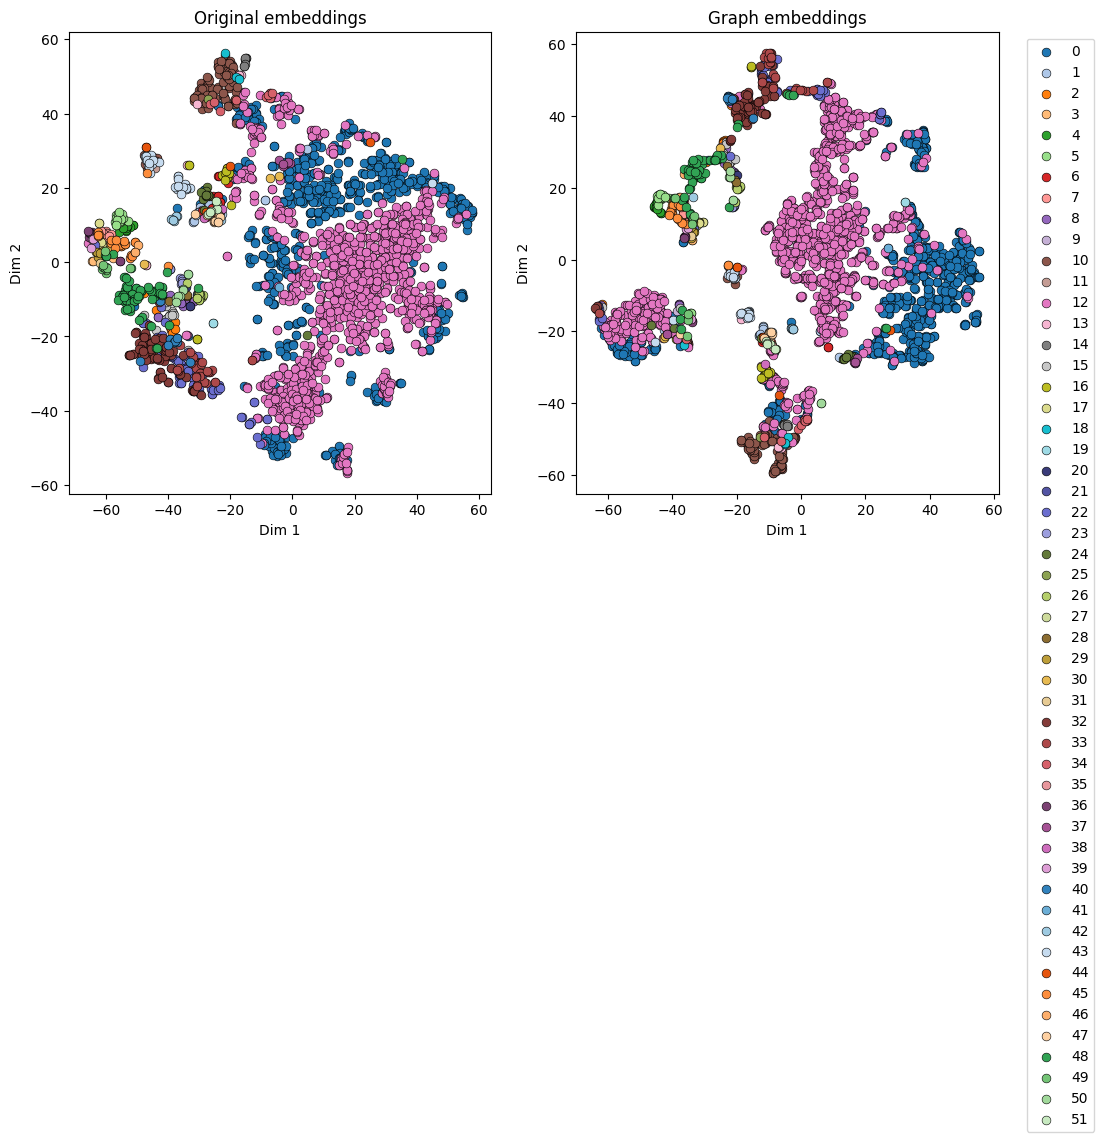

In [30]:
from utils import load_yaml

import torch
from datasets import load_dataset


base_dir = f'../outputs/{llm}+{sentence_model}'
setting = 'desc_sim_hetero_examples_llm_labels_100'

for dataset_name in ['ohsumed-single', 'agnews', 'r8', 'r52']:
    dataset_config = load_yaml(f'../configs/datasets/{dataset_name}.yaml')
    id2label = dataset_config['id2label']
    dataset = load_dataset(dataset_config['path'])
    true = torch.tensor(dataset['test'][dataset_config['label_feature']])

    fig,axs = plt.subplots(ncols=2, figsize=(12, 6))

    labels = true
    # labels = torch.load(f'{base_dir}/{dataset_name}/{setting}/0/propagated_labels.pt')

    embeddings = torch.load(f'../cache/{dataset_name}/embeddings_Qwen--Qwen3-VL-Embedding-2B.pt')
    plot_embedding_sets({'embeddings': embeddings, 'labels': labels}, ax=axs[0])

    axs[0].get_legend().remove()
    axs[0].set_title('Original embeddings')

    embeddings = torch.load(f'{base_dir}/{dataset_name}/{setting}/0/graph_embs.pt')
    data = torch.load(f'{base_dir}/{dataset_name}/{setting}/0/data.pt', weights_only=False)
    embeddings = embeddings[:len(labels)]
    plot_embedding_sets({'embeddings': embeddings, 'labels': labels}, ax=axs[1])

    axs[1].set_title('Graph embeddings')

    fig.savefig(f'figures/{dataset_name}_embs.pdf')
    

### Connected components

In [ ]:
import networkx as nx
from torch_geometric.data import Data, HeteroData
from torch_geometric.utils import to_networkx


def list_connected_components(data, verbose=True):
    if isinstance(data, HeteroData):
        homo = data.to_homogeneous()
        G = to_networkx(homo, to_undirected=True, remove_self_loops=False)
        node_type_names = list(data.node_types)
        components = []

        for cid, comp_nodes in enumerate(nx.connected_components(G)):
            node_dict = {}

            for node in comp_nodes:
                node_type_id = int(homo.node_type[node])
                node_type = node_type_names[node_type_id]

                local_idx = int(homo.n_id[node]) if hasattr(homo, 'n_id') else node

                node_dict.setdefault(node_type, []).append(local_idx)

            comp_info = {
                'component_id': cid,
                'num_nodes': len(comp_nodes),
                'nodes': node_dict,
            }

            components.append(comp_info)

    elif isinstance(data, Data):
        G = to_networkx(data, to_undirected=True, remove_self_loops=False)

        components = []

        for cid, comp_nodes in enumerate(nx.connected_components(G)):
            components.append(
                {
                    'component_id': cid,
                    'num_nodes': len(comp_nodes),
                    'nodes': set(comp_nodes),
                }
            )

    components.sort(key=lambda x: x['num_nodes'], reverse=True)

    if verbose:
        print(f'Found {len(components)} connected components:\n')

        for comp in components:
            print(f'Component {comp['component_id']:3d}: {comp['num_nodes']:6d} nodes')

            if isinstance(data, HeteroData):
                for node_type, nodes in comp['nodes'].items():
                    print(f'\t{node_type:15s}: {len(nodes):6d}')

    return components

In [50]:
for dataset_name in ['ohsumed-single', 'agnews', 'r8', 'r52']:
    for setting in ('base', 'hetero'):
        setting = f'desc_sim_{setting}_llm_labels_100'
        data = torch.load(f'{base_dir}/{dataset_name}/{setting}/0/data.pt', weights_only=False)
        print(dataset_name, setting)
        components = list_connected_components(data)
        print()
        print()

ohsumed-single desc_sim_base_llm_labels_100
Found 1 connected components:

Component   0:   4043 nodes


ohsumed-single desc_sim_hetero_llm_labels_100
Found 6 connected components:

Component   0:   4220 nodes
    text           :   4043
    description    :    177
Component   1:      1 nodes
    description    :      1
Component   2:      1 nodes
    description    :      1
Component   3:      1 nodes
    description    :      1
Component   4:      1 nodes
    description    :      1
Component   5:      1 nodes
    description    :      1


agnews desc_sim_base_llm_labels_100
Found 1 connected components:

Component   0:   7600 nodes


agnews desc_sim_hetero_llm_labels_100
Found 1 connected components:

Component   0:   7626 nodes
    text           :   7600
    description    :     26


r8 desc_sim_base_llm_labels_100
Found 1 connected components:

Component   0:   2189 nodes


r8 desc_sim_hetero_llm_labels_100
Found 2 connected components:

Component   0:   2243 nodes
    text      

In [72]:
import torch


i = 1

kmeans_sample_ids = torch.load('../cache/r52/kmeans_sample_100.pt')

knn_labels = torch.load(f'../outputs/AxionML--Qwen3.5-9B-NVFP4+Qwen--Qwen3-VL-Embedding-2B/r52/desc_sim_hetero_examples_llm_labels_100/{i}/knn_labels.pt')

llm_labels = torch.load(f'../cache/r52/AxionML--Qwen3.5-9B-NVFP4/{i}/labels.pt')
mask = torch.zeros_like(llm_labels, dtype=torch.bool)
mask[kmeans_sample_ids] = True
llm_labels[~mask] = -1

propagated_labels = torch.load(f'../outputs/AxionML--Qwen3.5-9B-NVFP4+Qwen--Qwen3-VL-Embedding-2B/r52/desc_sim_hetero_examples_llm_labels_100/{i}/propagated_labels.pt')

from sklearn.metrics import classification_report

pseudo_labels = knn_labels.clone()
pseudo_labels[llm_labels != -1] = llm_labels[llm_labels != -1]

print(classification_report(true[propagated_labels != -1], propagated_labels[propagated_labels != -1], zero_division=0))

              precision    recall  f1-score   support

           0       0.97      0.86      0.91       696
           1       0.85      0.89      0.87        19
           2       0.00      0.00      0.00         9
           3       0.00      0.00      0.00         5
           4       0.83      1.00      0.91        15
           5       0.87      0.91      0.89        22
           6       0.92      0.85      0.88        13
           7       0.75      1.00      0.86         9
           8       0.76      0.94      0.84        17
           9       0.00      0.00      0.00         1
          10       0.99      0.78      0.87       121
          11       0.00      0.00      0.00         3
          12       0.97      0.90      0.94      1083
          13       0.13      1.00      0.23         7
          14       0.00      0.00      0.00         8
          15       0.50      0.60      0.55        15
          16       0.66      0.95      0.78        20
          17       0.56    

In [63]:
from datasets import load_dataset


dataset = load_dataset('joao-luz/r52')
true = torch.tensor(dataset['test']['label'])

In [36]:
(llm_labels != -1).sum()

tensor(100)

In [22]:
knn_labels.shape

torch.Size([4043])

In [24]:
(knn_labels != -1).sum()

tensor(1349)

In [37]:
((knn_labels != -1) | (llm_labels != -1)).sum()

tensor(1405)

In [64]:
pseudo_labels = knn_labels.clone()
pseudo_labels[llm_labels != -1] = llm_labels[llm_labels != -1]

In [ ]:
from sklearn.metrics import classification_report

pseudo_labels = knn_labels.clone()
pseudo_labels[llm_labels != -1] = llm_labels[llm_labels != -1]
print(classification_report(true[propagated_labels != -1], propagated_labels[propagated_labels != -1], zero_division=0))

              precision    recall  f1-score   support

           0       0.97      0.86      0.91       696
           1       0.85      0.89      0.87        19
           2       0.00      0.00      0.00         9
           3       0.00      0.00      0.00         5
           4       0.83      1.00      0.91        15
           5       0.87      0.91      0.89        22
           6       0.92      0.85      0.88        13
           7       0.75      1.00      0.86         9
           8       0.76      0.94      0.84        17
           9       0.00      0.00      0.00         1
          10       0.99      0.78      0.87       121
          11       0.00      0.00      0.00         3
          12       0.97      0.90      0.94      1083
          13       0.13      1.00      0.23         7
          14       0.00      0.00      0.00         8
          15       0.50      0.60      0.55        15
          16       0.66      0.95      0.78        20
          17       0.56    

In [ ]:
(propagated_labels == -1)